# 2025 NHIS Healthcare Access — Survey Analysis and Predictive Modeling

This notebook extends the exploratory analysis into two deliberately separate tracks:

1. **Population inference:** survey-weighted estimates of delayed medical care because of cost, using the final Sample Adult weight and public stratum/PSU identifiers.
2. **Predictive modeling:** held-out logistic-regression models that distinguish adults who report delayed care using a curated predictor set. Because NHIS is cross-sectional, these are retrospective classification models rather than prospective forecasts.

Income is handled through the official 10 multiply imputed Sample Adult income records. Survey estimates are calculated within each completed income dataset and pooled; predictive income models are run separately across all 10 imputations as a sensitivity analysis.

The primary outcome is `MEDDL12M_A` (delayed medical care because of cost in the past 12 months). The closely related `MEDNG12M_A` outcome is excluded from predictors to prevent leakage.

> **Data source:** National Center for Health Statistics, National Health Interview Survey, 2025. Analyses, interpretations, and conclusions are those of the author and not NCHS. Raw public-use microdata are not stored in the Git repository.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"
ASSETS = ROOT / "assets"
ASSETS.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Survey-weighted prevalence

The survey analysis uses Taylor linearization with the NHIS public final annual weight (`WTFA_A`), variance stratum (`PSTRAT`), and variance PSU (`PPSU`). Confidence intervals use the resulting design degrees of freedom.

In [2]:
overall = pd.read_csv(PROCESSED / "survey_overall.csv")
overall

,dimension,level,unweighted_n,unweighted_positives,weighted_prevalence,standard_error,ci_lower,ci_upper,design_df
0,Overall,All adults,24021,1564,0.0705,0.0022,0.0662,0.0748,562


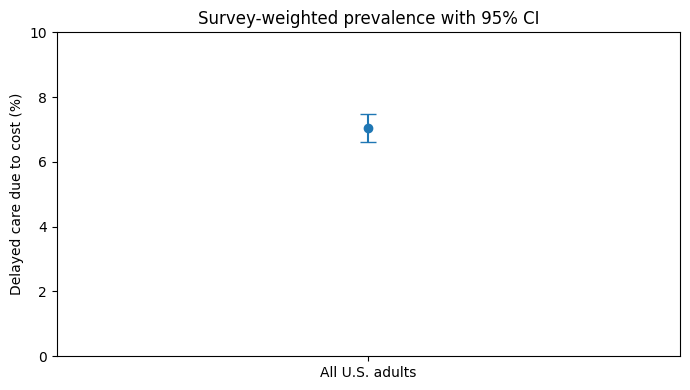

In [3]:
row = overall.iloc[0]
fig, ax = plt.subplots(figsize=(7, 4))
y = row["weighted_prevalence"] * 100
err_low = (row["weighted_prevalence"] - row["ci_lower"]) * 100
err_high = (row["ci_upper"] - row["weighted_prevalence"]) * 100
ax.errorbar(["All U.S. adults"], [y], yerr=[[err_low], [err_high]], fmt="o", capsize=6)
ax.set_ylabel("Delayed care due to cost (%)")
ax.set_title("Survey-weighted prevalence with 95% CI")
ax.set_ylim(0, max(10, row["ci_upper"] * 100 + 2))
fig.tight_layout()
fig.savefig(ASSETS / "survey_weighted_prevalence_ci.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Access-related subgroup differences

These are descriptive population estimates, not causal effects. The two access variables below are especially policy-relevant correlates measured in the same cross-sectional interview; their timing relative to delayed care during the prior 12 months is not established.

In [4]:
groups = pd.read_csv(PROCESSED / "survey_group_estimates.csv")
access = groups[groups["dimension"].isin(["Insurance status", "Usual place of care"])].copy()
access[["dimension", "level", "unweighted_n", "weighted_prevalence", "ci_lower", "ci_upper"]]

,dimension,level,unweighted_n,weighted_prevalence,ci_lower,ci_upper
0,Insurance status,Covered,22344,0.0512,0.0475,0.0548
1,Insurance status,Not covered,1614,0.2659,0.2397,0.2922
2,Usual place of care,One usual place,21333,0.0609,0.0567,0.0651
3,Usual place of care,No usual place,2090,0.1502,0.1309,0.1694
4,Usual place of care,More than one usual place,587,0.0887,0.0601,0.1172


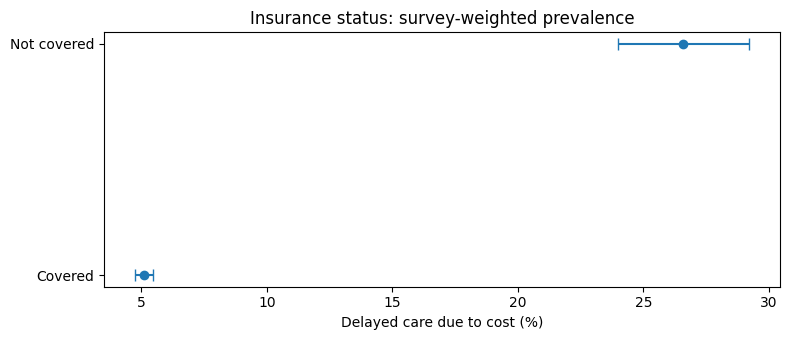

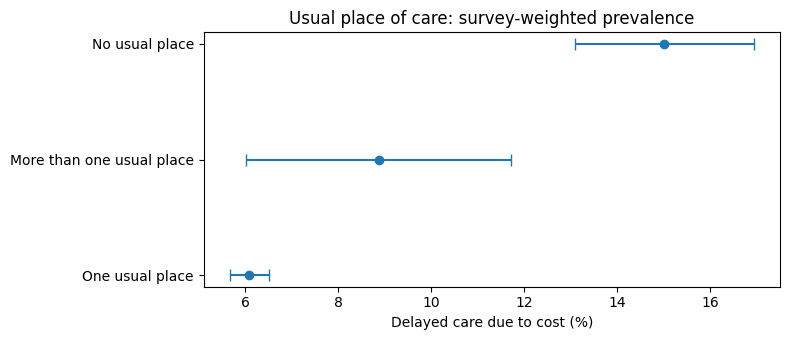

In [5]:
for dimension in ["Insurance status", "Usual place of care"]:
    plot = groups[groups["dimension"] == dimension].copy().sort_values("weighted_prevalence")
    fig, ax = plt.subplots(figsize=(8, max(3.5, 0.7 * len(plot))))
    values = plot["weighted_prevalence"] * 100
    lower = (plot["weighted_prevalence"] - plot["ci_lower"]) * 100
    upper = (plot["ci_upper"] - plot["weighted_prevalence"]) * 100
    ax.errorbar(values, plot["level"], xerr=[lower, upper], fmt="o", capsize=4)
    ax.set_xlabel("Delayed care due to cost (%)")
    ax.set_title(f"{dimension}: survey-weighted prevalence")
    fig.tight_layout()
    filename = "survey_insurance_ci.png" if dimension == "Insurance status" else "survey_usual_place_ci.png"
    fig.savefig(ASSETS / filename, dpi=160, bbox_inches="tight")
    plt.show()

## 3. Income analysis across all 10 imputations

The Adult file contains only the first imputed income values. This project instead uses the separate Sample Adult Income file so estimates are calculated in each of the 10 completed datasets and pooled. The four poverty bands below collapse the detailed `RATCAT_A` categories into policy-readable groups.

In [6]:
income = pd.read_csv(PROCESSED / "income_pooled_estimates.csv")
income[["poverty_band", "weighted_prevalence", "standard_error", "ci_lower", "ci_upper", "imputations"]]

,poverty_band,weighted_prevalence,standard_error,ci_lower,ci_upper,imputations
0,Below 100% FPL,0.1038,0.0090,0.0862,0.1214,10
1,100-199% FPL,0.1107,0.0066,0.0977,0.1237,10
2,200-399% FPL,0.0860,0.0042,0.0779,0.0942,10
3,400%+ FPL,0.0358,0.0022,0.0314,0.0401,10


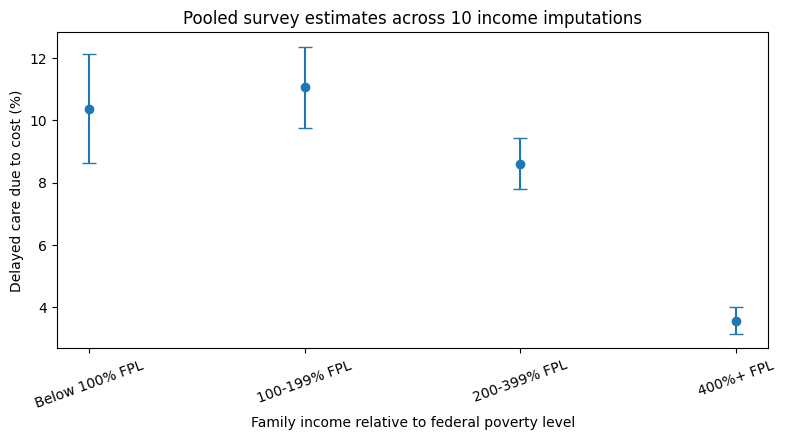

In [7]:
income_plot = income.copy()
fig, ax = plt.subplots(figsize=(8, 4.5))
values = income_plot["weighted_prevalence"] * 100
lower = (income_plot["weighted_prevalence"] - income_plot["ci_lower"]) * 100
upper = (income_plot["ci_upper"] - income_plot["weighted_prevalence"]) * 100
ax.errorbar(income_plot["poverty_band"], values, yerr=[lower, upper], fmt="o", capsize=5)
ax.set_ylabel("Delayed care due to cost (%)")
ax.set_xlabel("Family income relative to federal poverty level")
ax.set_title("Pooled survey estimates across 10 income imputations")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(ASSETS / "income_pooled_prevalence_ci.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Held-out predictive performance

The predictive models use a fixed 75/25 stratified train/test split. They classify respondents who report delayed care during the prior 12 months; they should not be interpreted as forecasts of future delayed care. Final survey weights are used as sample weights in model fitting and evaluation, but `PSTRAT` and `PPSU` are **not** used to claim coefficient-level survey inference. The core model contains demographics, family structure, employment, housing, nativity, insurance/access, region, and urban-rural classification. The expanded model adds general health and functioning difficulty.

In [8]:
metrics = pd.read_csv(PROCESSED / "model_metrics.csv")
metrics[[
    "model", "weighted_roc_auc", "weighted_average_precision",
    "weighted_brier_score", "weighted_log_loss",
    "weighted_precision_at_0_5", "weighted_recall_at_0_5"
]]

,model,weighted_roc_auc,weighted_average_precision,weighted_brier_score,weighted_log_loss,weighted_precision_at_0_5,weighted_recall_at_0_5
0,prevalence_baseline,0.5000,0.0720,0.0668,0.2587,0.0000,0.0000
1,core_logistic,0.7382,0.2306,0.0612,0.2296,0.3793,0.0137
2,expanded_logistic,0.7729,0.2719,0.0599,0.2221,0.5788,0.0774
3,expanded_gradient_boosting,0.7807,0.2667,0.0599,0.2205,0.6571,0.0377


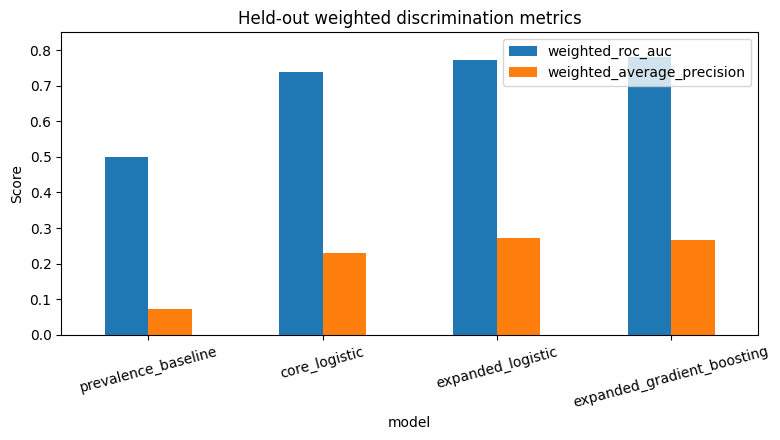

In [9]:
plot_metrics = metrics.set_index("model")[["weighted_roc_auc", "weighted_average_precision"]]
ax = plot_metrics.plot(kind="bar", figsize=(8, 4.5))
ax.set_ylabel("Score")
ax.set_title("Held-out weighted discrimination metrics")
ax.set_ylim(0, 0.85)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(ASSETS / "model_discrimination_metrics.png", dpi=160, bbox_inches="tight")
plt.show()

### ROC and precision-recall curves

Because the positive class is uncommon, precision-recall is particularly important. A 0.50 probability threshold is intentionally **not** treated as an operational decision threshold; the project reports ranking/calibration metrics first.

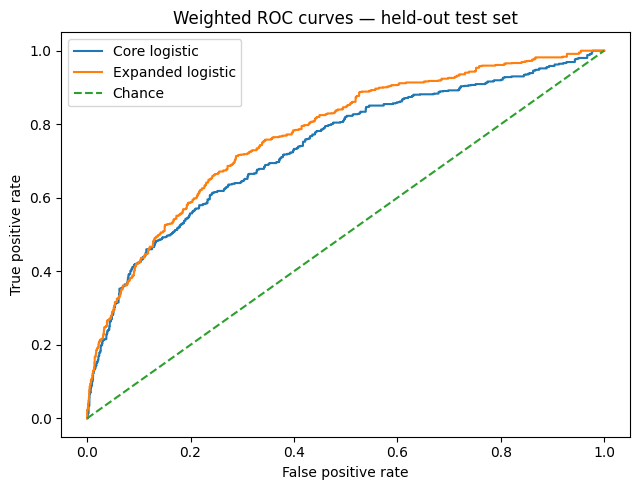

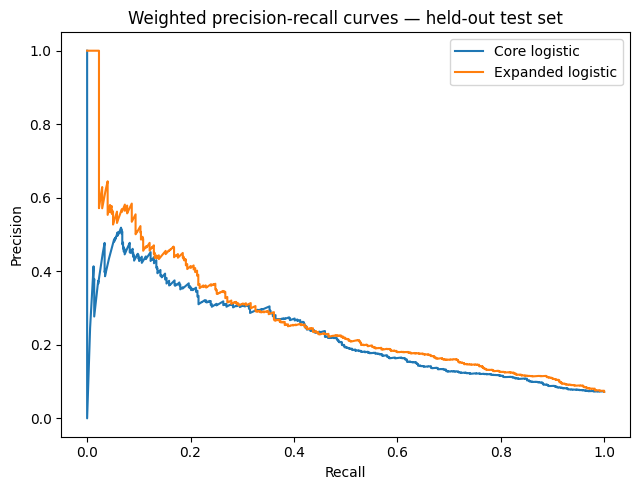

In [10]:
pred = pd.read_csv(PROCESSED / "test_predictions.csv", dtype={"HHX": str})
y = pred["delayed_care_cost"].astype(int)
w = pred["WTFA_A"].astype(float)

fig, ax = plt.subplots(figsize=(6.5, 5))
for label, col in [("Core logistic", "core_probability"), ("Expanded logistic", "expanded_probability")]:
    fpr, tpr, _ = roc_curve(y, pred[col], sample_weight=w)
    ax.plot(fpr, tpr, label=label)
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Weighted ROC curves — held-out test set")
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "model_roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for label, col in [("Core logistic", "core_probability"), ("Expanded logistic", "expanded_probability")]:
    precision, recall, _ = precision_recall_curve(y, pred[col], sample_weight=w)
    ax.plot(recall, precision, label=label)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Weighted precision-recall curves — held-out test set")
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "model_precision_recall_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Model coefficients as descriptive signals

These coefficients are useful for understanding what the regularized predictive model is using, but they are **not survey-adjusted causal or inferential odds ratios**. Numeric predictors are standardized; categorical coefficients are relative to the one-hot encoder's omitted reference category.

In [11]:
coef = pd.read_csv(PROCESSED / "model_coefficients_expanded.csv")
coef.head(15)[["feature", "coefficient", "odds_ratio"]]

,feature,coefficient,odds_ratio
0,cat__general_health_Poor,1.9521,7.0433
1,cat__insurance_status_Not covered,1.6830,5.3818
2,cat__general_health_Fair,1.2971,3.6587
3,cat__functioning_difficulty_Yes,0.7841,2.1904
4,cat__race_ethnicity_Non-Hispanic Asian,-0.6833,0.5049
5,cat__general_health_Good,0.6480,1.9117
6,cat__marital_status_Never married,-0.6293,0.5330
7,cat__education_Professional or doctoral degree,0.5545,1.7411
8,cat__education_GED or equivalent,0.5503,1.7338
9,"cat__education_Associate degree, occupational/...",0.5158,1.6749


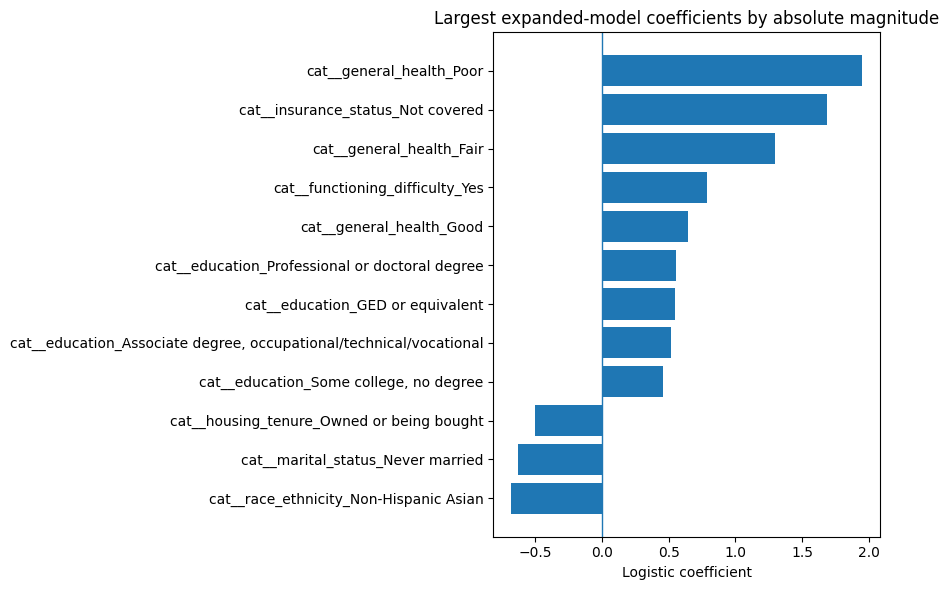

In [12]:
top = coef.head(12).sort_values("coefficient")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["feature"], top["coefficient"])
ax.axvline(0, linewidth=1)
ax.set_xlabel("Logistic coefficient")
ax.set_title("Largest expanded-model coefficients by absolute magnitude")
fig.tight_layout()
fig.savefig(ASSETS / "expanded_model_coefficients.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Income-model sensitivity across imputations

Each income-enhanced logistic model is refit separately for imputation 1 through 10 using the same train/test household split. The variation across runs shows how much predictive performance depends on which plausible imputed income values are used.

In [13]:
income_runs = pd.read_csv(PROCESSED / "income_model_runs.csv")
income_summary = pd.read_csv(PROCESSED / "income_model_summary.csv")
income_summary[[
    "model", "weighted_roc_auc_mean", "weighted_roc_auc_sd",
    "weighted_average_precision_mean", "weighted_brier_score_mean"
]]

,model,weighted_roc_auc_mean,weighted_roc_auc_sd,weighted_average_precision_mean,weighted_brier_score_mean
0,core_plus_income_logistic,0.7513,0.0015,0.2311,0.0612
1,expanded_plus_income_logistic,0.7812,0.0010,0.2711,0.0600


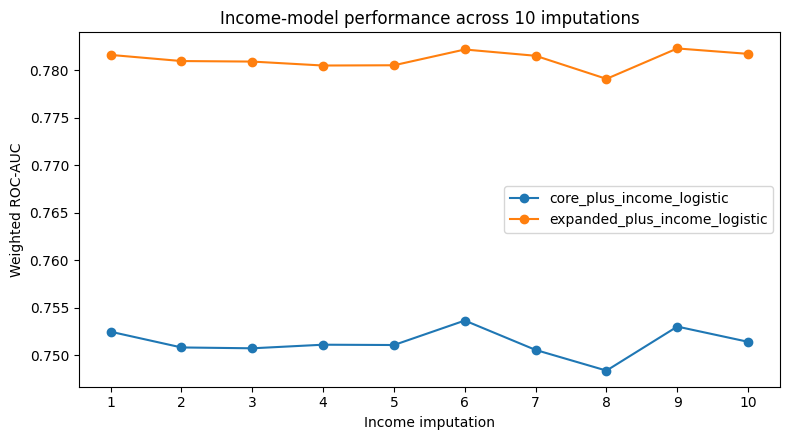

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for family, grp in income_runs.groupby("model_family"):
    ax.plot(grp["imputation"], grp["weighted_roc_auc"], marker="o", label=family)
ax.set_xlabel("Income imputation")
ax.set_ylabel("Weighted ROC-AUC")
ax.set_title("Income-model performance across 10 imputations")
ax.set_xticks(range(1, 11))
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "income_model_auc_sensitivity.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Interpretation

The analysis supports several portfolio-level conclusions:

- Cost-related delayed care is uncommon overall but strongly concentrated in some access and socioeconomic groups.
- Insurance status and having a usual place of care show large descriptive prevalence differences.
- Lower-income groups have substantially higher pooled delayed-care prevalence than adults at 400%+ of the federal poverty level.
- The core logistic model provides meaningful discrimination beyond prevalence alone; adding health status/functioning improves it further.
- Adding imputed poverty ratio produces a modest, stable improvement across all 10 imputations.

These results remain **associational and predictive**, not causal. The statistical estimates account for the public survey design, while the machine-learning models are evaluated as prediction tools rather than as survey-regression inference.